# 04 — GRU/LSTM over weekly activity (Person 3) · owner: chad

**Task (same for all four of us):** predict the probability that a customer buys at least once
between 1–30 Oct 2024, using only data up to 30 Sep 2024.

**My variant:** instead of one flat row of totals, my network reads each customer's history
**week by week** with a recurrent layer (GRU or LSTM), so it can see trends such as
"was active, now slowing down" (see `02_eda_weekly_chad`).

**Shared with the team, never redefined here:** `train_features.csv`, the split in `splits.csv`,
the preprocessor and the metrics, all from `src/data_prep.py`; the baselines from
`01_baselines.ipynb` (`results/baseline_results.csv`).

| Section | What it does |
|---|---|
| 0 | Setup |
| 1 | Load the shared data and split |
| 2 | Prepare the inputs: static features + weekly sequences |
| 3 | Baselines: the team's results + a fair extra check |
| 4 | My model: GRU over the weekly history |
| 5 | Tuning (logged) and stability |
| 6 | Final evaluation on the test split (used once) |
| 7 | Trust checks |
| 8 | Save · 9 Conclusions |

## 0. Setup

In [1]:
import random
import sys
import time
from pathlib import Path

# Find the project root (the folder that contains src/data_prep.py), like the team's notebooks.
ROOT = Path.cwd()
while not (ROOT / "src" / "data_prep.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score

# Shared team code: same data, split, preprocessing and metrics for everyone
from data_prep import (CATEGORICAL_COLS, ID_COL, MODELS_DIR, RESULTS_DIR, SEED, TARGET_COL,
                       best_f1_threshold, build_preprocessor, evaluate, get_splits, load_data,
                       precision_at_top, split_xy)
from shopsphere.config import DATA_PROCESSED, FIGURES_DIR


def set_seed(seed=SEED):
    """Same seed everywhere = same results every run (reproducible)."""
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
set_seed()

FIGURES_DIR.mkdir(parents=True, exist_ok=True); RESULTS_DIR.mkdir(exist_ok=True); MODELS_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "font.size": 10})
BLUE, ORANGE, GREY = "#2a6f97", "#e07a1f", "#9aa5b1"
def save(fig, name):
    fig.tight_layout(); fig.savefig(FIGURES_DIR / f"chad_{name}.png", bbox_inches="tight", dpi=150); plt.show()

## 1. Load the shared data and split

In [2]:
df = load_data()                                   # train_features.csv: features + target
train, val, test = get_splits(df)                  # the team's one split (splits.csv)
X_train, y_train = split_xy(train)
X_val, y_val = split_xy(val)
X_test, y_test = split_xy(test)
for name, yy in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    print(f"{name:<11} {len(yy):>6,} rows   buy rate {yy.mean():.3f}")

train       44,800 rows   buy rate 0.146
validation   9,600 rows   buy rate 0.146
test         9,600 rows   buy rate 0.146


## 2. Prepare the inputs
### 2a. Static features (the team's preprocessor, fitted on TRAIN only)

In [3]:
pre = build_preprocessor(X_train).fit(X_train)
dense = lambda a: a.toarray() if hasattr(a, "toarray") else np.asarray(a)
Xtr, Xva, Xte = (dense(pre.transform(X)).astype(np.float32) for X in (X_train, X_val, X_test))
print("static input shape:", Xtr.shape)

static input shape: (44800, 183)


### 2b. The weekly sequences (my model's main input)
`weekly_sequences.npz` has, for every customer, 104 weeks × 4 numbers (orders, spend, sessions,
cart adds), oldest week first and the week ending 30 Sep last. Built by `src/weekly_sequences.py`.

1. put the rows in the same customer order as `train` / `val` / `test`
2. `log(1+x)`: spend and session counts are very skewed (EDA)
3. standardise each of the 4 channels with the mean / std of the **training customers only**

In [4]:
wk = np.load(DATA_PROCESSED / "weekly_sequences.npz")
row_of = pd.Series(np.arange(len(wk["customer_id"])), index=wk["customer_id"])
raw = {name: np.log1p(wk["seq"][row_of[part[ID_COL]].values])
       for name, part in [("train", train), ("val", val), ("test", test)]}
CH_MEAN = raw["train"].mean(axis=(0, 1))           # one mean per channel, TRAIN only
CH_STD = raw["train"].std(axis=(0, 1))
SEQ = {name: ((a - CH_MEAN) / CH_STD).astype(np.float32) for name, a in raw.items()}
print("sequence arrays:", {k: v.shape for k, v in SEQ.items()}, "| channels:", list(wk["channels"]))
print("train mean per channel after scaling:", SEQ["train"].mean(axis=(0, 1)).round(3))

sequence arrays: {'train': (44800, 104, 4), 'val': (9600, 104, 4), 'test': (9600, 104, 4)} | channels: [np.str_('orders'), np.str_('spend'), np.str_('sessions'), np.str_('cart_adds')]
train mean per channel after scaling: [-0.     0.     0.002  0.001]


## 3. Baselines
### 3a. The team's baselines (from `01_baselines.ipynb`)
Always-0, the recency rule, logistic regression and LightGBM were built once for the whole team.
I read their saved results instead of re-implementing them.

In [5]:
team = pd.read_csv(RESULTS_DIR / "baseline_results.csv")
results = [r for r in team.drop(columns="accuracy", errors="ignore").to_dict("records")]
team[team["split"] == "test"].set_index("model")[["pr_auc", "roc_auc", "precision", "recall", "f1", "precision_top10"]].round(3)

,pr_auc,roc_auc,precision,recall,f1,precision_top10
model,,,,,,
Always 0,0.146,0.500,0.000,0.000,0.000,0.146
Recency rule,0.366,0.795,0.363,0.614,0.457,0.437
Logistic regression,0.577,0.873,0.489,0.612,0.543,0.626
LightGBM,0.576,0.874,0.492,0.606,0.543,0.605


### 3b. Extra baseline: is any gain from the GRU, or just from the extra weekly data?
My model sees weekly data the other baselines don't. To be fair, I retrain the team's best LightGBM
set-up (from `01_baselines`: 15 leaves, learning rate 0.03, min_child_samples 20) twice:
on the static features alone, and with the last 52 weeks × 4 channels added as 208 extra columns.
If my GRU only matches the second one, the gain came from the data, not from reading it as a sequence.

In [6]:
category_levels = {c: sorted(X_train[c].unique()) for c in CATEGORICAL_COLS}
def to_lgbm_frame(X, seq=None):
    X = X.copy()
    for c in CATEGORICAL_COLS:
        X[c] = pd.Categorical(X[c], categories=category_levels[c])
    if seq is not None:                                   # add week_t_channel columns
        flat = seq[:, -52:].reshape(len(X), -1)
        cols = [f"w{t}_{ch}" for t in range(52) for ch in wk["channels"]]
        X = pd.concat([X.reset_index(drop=True), pd.DataFrame(flat, columns=cols)], axis=1)
    return X

def fit_team_lgbm(Xl_tr, Xl_va):
    m = lgb.LGBMClassifier(n_estimators=2000, num_leaves=15, learning_rate=0.03, min_child_samples=20,
                           scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
                           metric="average_precision", random_state=SEED, deterministic=True,
                           force_row_wise=True, verbose=-1)
    m.fit(Xl_tr, y_train, eval_set=[(Xl_va, y_val)], callbacks=[lgb.early_stopping(50, verbose=False)])
    return m

test_scores, thresholds = {}, {}
def add(name, val_scores, test_scores_):
    thr = best_f1_threshold(y_val, val_scores)                       # threshold chosen on VALIDATION
    results.append({"model": name, "split": "val", **evaluate(y_val, val_scores, thr)})
    results.append({"model": name, "split": "test", **evaluate(y_test, test_scores_, thr)})
    test_scores[name], thresholds[name] = test_scores_, thr

for label, use_seq in [("LightGBM (retrained, check)", False), ("LightGBM + weekly data", True)]:
    m = fit_team_lgbm(to_lgbm_frame(X_train, SEQ["train"] if use_seq else None),
                      to_lgbm_frame(X_val, SEQ["val"] if use_seq else None))
    add(label, m.predict_proba(to_lgbm_frame(X_val, SEQ["val"] if use_seq else None))[:, 1],
        m.predict_proba(to_lgbm_frame(X_test, SEQ["test"] if use_seq else None))[:, 1])
pd.DataFrame(results).query("split == 'val'").set_index("model")[["pr_auc", "roc_auc", "f1"]].round(4)

C:\Users\Chadk\AppData\Local\Temp\claude\5765d0dc6b764144\786631ca-e990-4a55-afc0-12f67601ce53\scratchpad\venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


C:\Users\Chadk\AppData\Local\Temp\claude\5765d0dc6b764144\786631ca-e990-4a55-afc0-12f67601ce53\scratchpad\venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


,pr_auc,roc_auc,f1
model,,,
Always 0,0.1457,0.5000,0.0000
Recency rule,0.3663,0.7974,0.4623
Logistic regression,0.5623,0.8680,0.5353
LightGBM,0.5627,0.8689,0.5316
"LightGBM (retrained, check)",0.5627,0.8689,0.5316
LightGBM + weekly data,0.5621,0.8695,0.5342


**Check:** the retrained LightGBM should score the same as the team's LightGBM row, which shows I
am using exactly the same data, split and metrics as the team.

## 4. My deep learning model: a GRU over the weekly history

```
weekly history (52 weeks × 4) ─► GRU (hidden) ─► last hidden state ─┐
                                                                    ├─► Dense 64 ─► ReLU ─► Dropout ─► Dense 1 ─► sigmoid
static features ─────────────────► Dense 64 ─► ReLU ───────────────┘      (hybrid only)
```
* A **GRU** reads one week at a time and keeps a running "memory" (the hidden state). After the
  last week, that memory summarises the whole history, including its trend.
* **LSTM** is a similar recurrent layer with an extra memory cell; compared in tuning.
* **Hybrid** = also feed the team's static features (tier, loyalty score, recency…).
* Training recipe shared with the team: weighted loss (`pos_weight ≈ 5.86`), Adam, batch 512,
  early stopping on validation PR-AUC.

In [7]:
class SeqNet(nn.Module):
    def __init__(self, n_static=0, cell="GRU", hidden=64, dropout=0.3):
        super().__init__()
        rnn = nn.GRU if cell == "GRU" else nn.LSTM
        self.cell = cell
        self.rnn = rnn(input_size=4, hidden_size=hidden, batch_first=True)
        self.use_static = n_static > 0
        joined = hidden
        if self.use_static:
            self.static = nn.Sequential(nn.Linear(n_static, 64), nn.ReLU())
            joined += 64
        self.head = nn.Sequential(nn.Linear(joined, 64), nn.ReLU(), nn.Dropout(dropout), nn.Linear(64, 1))

    def forward(self, seq, static=None):
        _, h = self.rnn(seq)                     # h = hidden state after the LAST week
        if self.cell == "LSTM":
            h = h[0]                             # LSTM returns (hidden, cell); we use the hidden state
        z = h[-1]                                # shape (batch, hidden)
        if self.use_static:
            z = torch.cat([z, self.static(static)], dim=1)   # join the two views of the customer
        return self.head(z).squeeze(1)           # a logit; sigmoid turns it into P(buy)


to_t = lambda a: torch.tensor(a, dtype=torch.float32)
S_tr, S_va, S_te = to_t(Xtr), to_t(Xva), to_t(Xte)                          # static
Q_tr, Q_va, Q_te = to_t(SEQ["train"]), to_t(SEQ["val"]), to_t(SEQ["test"])  # sequences (104 weeks)
ytr_t = torch.tensor(y_train, dtype=torch.float32)
POS_WEIGHT = (y_train == 0).sum() / (y_train == 1).sum()
print(f"pos_weight = {POS_WEIGHT:.2f}")


def predict_proba(model, Q, S, weeks):
    model.eval()                                 # dropout OFF
    out = []
    with torch.no_grad():
        for i in range(0, len(Q), 4096):         # in chunks to save memory
            out.append(torch.sigmoid(model(Q[i:i + 4096, -weeks:], S[i:i + 4096])))
    return torch.cat(out).numpy()


def train_seq(weeks=52, cell="GRU", hidden=64, dropout=0.3, static=True, lr=1e-3, batch_size=512,
              max_epochs=25, patience=4, seed=SEED, verbose=False):
    set_seed(seed)
    model = SeqNet(S_tr.shape[1] if static else 0, cell, hidden, dropout)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(POS_WEIGHT, dtype=torch.float32))
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    history, best_ap, best_state, wait = [], -1, None, 0
    for epoch in range(1, max_epochs + 1):
        model.train()                            # dropout ON while learning
        perm = torch.randperm(len(Q_tr))
        total = 0.0
        for i in range(0, len(perm), batch_size):
            idx = perm[i:i + batch_size]
            opt.zero_grad()                                              # 1. clear old gradients
            loss = loss_fn(model(Q_tr[idx, -weeks:], S_tr[idx]), ytr_t[idx])   # 2. forward + loss
            loss.backward()                                              # 3. back-propagation (through time)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)            #    keep RNN gradients from exploding
            opt.step()                                                   # 4. update weights
            total += loss.item() * len(idx)
        val_ap = average_precision_score(y_val, predict_proba(model, Q_va, S_va, weeks))
        history.append({"epoch": epoch, "train_loss": total / len(perm), "val_pr_auc": val_ap})
        if verbose: print(f"epoch {epoch:>2}  loss {total/len(perm):.4f}  val PR-AUC {val_ap:.4f}")
        if val_ap > best_ap:                     # early stopping bookkeeping
            best_ap, wait = val_ap, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience: break
    model.load_state_dict(best_state)            # roll back to the best epoch
    return model, pd.DataFrame(history), best_ap

pos_weight = 5.86


### 4a. First model: GRU on the weekly history only (no static features)
The pure question: *how much can the network learn from the weekly pattern alone?*

In [8]:
t0 = time.time()
gru_only, hist_only, ap_only = train_seq(static=False, verbose=True)
print(f"GRU (weekly only) best validation PR-AUC: {ap_only:.4f}  ({time.time()-t0:.0f}s)")

epoch  1  loss 0.8994  val PR-AUC 0.5244


epoch  2  loss 0.8052  val PR-AUC 0.5412


epoch  3  loss 0.7957  val PR-AUC 0.5443


epoch  4  loss 0.7874  val PR-AUC 0.5483


epoch  5  loss 0.7822  val PR-AUC 0.5513


epoch  6  loss 0.7781  val PR-AUC 0.5511


... (15 outputs left out)

epoch 22  loss 0.7668  val PR-AUC 0.5594


epoch 23  loss 0.7642  val PR-AUC 0.5602


epoch 24  loss 0.7649  val PR-AUC 0.5594


epoch 25  loss 0.7645  val PR-AUC 0.5599
GRU (weekly only) best validation PR-AUC: 0.5602  (135s)


## 5. Tuning (evidence of optimisation)
One idea at a time, every run logged, chosen on **validation** PR-AUC only. Choices from the
project plan: sequence length (26 vs 52 weeks), hidden size, GRU vs LSTM, dropout, plus adding
the static features.

In [9]:
grid = [
    dict(name="r1 GRU, weekly only, 52w",        static=False),
    dict(name="r2 GRU + static, 52w (hybrid)",   static=True),
    dict(name="r3 hybrid, 26 weeks",             static=True, weeks=26),
    dict(name="r4 hybrid, hidden 32",            static=True, hidden=32),
    dict(name="r5 hybrid, LSTM instead of GRU",  static=True, cell="LSTM"),
    dict(name="r6 hybrid, dropout 0.1",          static=True, dropout=0.1),
    dict(name="r7 hybrid, dropout 0.5",          static=True, dropout=0.5),
]
log, models, hists = [], {}, {}
for cfg in grid:
    params = {k: v for k, v in cfg.items() if k != "name"}
    t0 = time.time()
    if cfg["name"].startswith("r1"):             # r1 was trained above, reuse it
        m, h, ap = gru_only, hist_only, ap_only
    else:
        m, h, ap = train_seq(**params)
    models[cfg["name"]], hists[cfg["name"]] = m, h
    log.append({"run": cfg["name"], **{k: str(v) for k, v in params.items()},
                "epochs": len(h), "val_pr_auc": round(ap, 4), "seconds": round(time.time() - t0, 1)})
    print(f"{cfg['name']:<34} val PR-AUC {ap:.4f}  epochs {len(h)}", flush=True)
tuning_log = pd.DataFrame(log).sort_values("val_pr_auc", ascending=False)
tuning_log.to_csv(RESULTS_DIR / "gru_chad_tuning_log.csv", index=False)
tuning_log

r1 GRU, weekly only, 52w           val PR-AUC 0.5602  epochs 25


r2 GRU + static, 52w (hybrid)      val PR-AUC 0.5653  epochs 10


r3 hybrid, 26 weeks                val PR-AUC 0.5651  epochs 10


r4 hybrid, hidden 32               val PR-AUC 0.5660  epochs 9


r5 hybrid, LSTM instead of GRU     val PR-AUC 0.5643  epochs 11


r6 hybrid, dropout 0.1             val PR-AUC 0.5661  epochs 10


r7 hybrid, dropout 0.5             val PR-AUC 0.5651  epochs 10


,run,static,epochs,val_pr_auc,seconds,weeks,hidden,cell,dropout
5,"r6 hybrid, dropout 0.1",True,10,0.5661,53.0,NaN,NaN,NaN,0.1
3,"r4 hybrid, hidden 32",True,9,0.5660,25.7,NaN,32,NaN,NaN
1,"r2 GRU + static, 52w (hybrid)",True,10,0.5653,52.3,NaN,NaN,NaN,NaN
6,"r7 hybrid, dropout 0.5",True,10,0.5651,52.9,NaN,NaN,NaN,0.5
2,"r3 hybrid, 26 weeks",True,10,0.5651,24.3,26,NaN,NaN,NaN
4,"r5 hybrid, LSTM instead of GRU",True,11,0.5643,34.1,NaN,NaN,LSTM,NaN
0,"r1 GRU, weekly only, 52w",False,25,0.5602,0.0,NaN,NaN,NaN,NaN


Best: r6 hybrid, dropout 0.1 {'weeks': 52, 'cell': 'GRU', 'hidden': 64, 'dropout': 0.1, 'static': True}


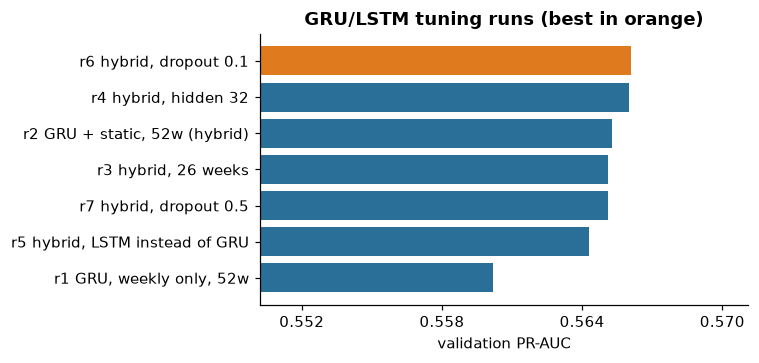

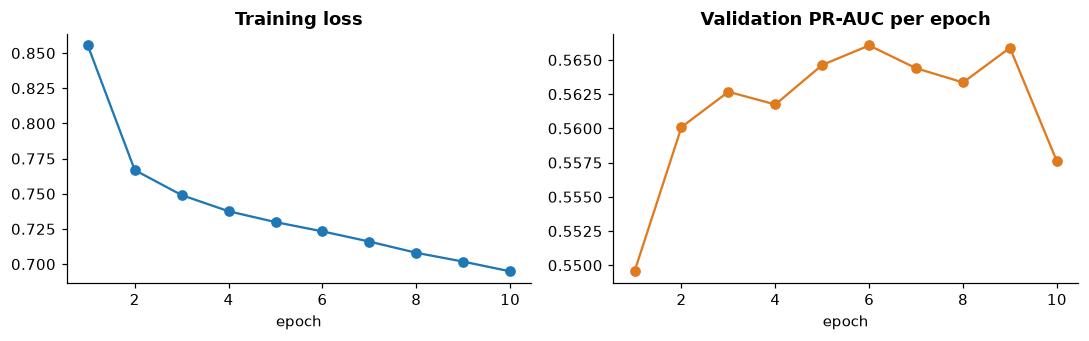

In [10]:
best_name = tuning_log.iloc[0]["run"]
best_cfg = {"weeks": 52, "cell": "GRU", "hidden": 64, "dropout": 0.3, "static": True}
best_cfg.update({k: v for k, v in next(c for c in grid if c["name"] == best_name).items() if k != "name"})
print("Best:", best_name, best_cfg)

fig, ax = plt.subplots(figsize=(7, 3.4))
tl = tuning_log.sort_values("val_pr_auc")
ax.barh(tl["run"], tl["val_pr_auc"], color=[ORANGE if r == best_name else BLUE for r in tl["run"]])
ax.set_xlim(tl["val_pr_auc"].min() - 0.01, tl["val_pr_auc"].max() + 0.005)
ax.xaxis.set_major_locator(plt.MaxNLocator(4))
ax.set_xlabel("validation PR-AUC"); ax.set_title("GRU/LSTM tuning runs (best in orange)")
save(fig, "31_gru_tuning_runs")

h = hists[best_name]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].plot(h["epoch"], h["train_loss"], marker="o"); axes[0].set_title("Training loss"); axes[0].set_xlabel("epoch")
axes[1].plot(h["epoch"], h["val_pr_auc"], marker="o", color=ORANGE); axes[1].set_title("Validation PR-AUC per epoch")
axes[1].set_xlabel("epoch")
save(fig, "30_gru_learning_curves")

### 5b. Stability: the best setting with 3 different seeds
If seeds change the score as much as the tuning choices did, the "best" run may be luck.

In [11]:
seed_scores = [tuning_log.iloc[0]["val_pr_auc"]]
for s in [1, 2]:
    _, _, ap = train_seq(**best_cfg, seed=s)
    seed_scores.append(ap)
print("Validation PR-AUC, seeds 42/1/2:", np.round(seed_scores, 4),
      f"→ mean {np.mean(seed_scores):.4f} ± {np.std(seed_scores):.4f}")
hybrid = tuning_log[tuning_log["static"] == "True"]["val_pr_auc"]
print(f"Spread across the hybrid tuning runs: {hybrid.max() - hybrid.min():.4f}")

Validation PR-AUC, seeds 42/1/2: [0.5661 0.5651 0.5635] → mean 0.5649 ± 0.0011
Spread across the hybrid tuning runs: 0.0018


## 6. Final evaluation on the TEST split (used once)
Final model = the best tuning run, plus the weekly-only GRU for comparison. Thresholds are chosen
on validation and reused unchanged on test, like the team's baselines.

In [12]:
final = models[best_name]; W = best_cfg["weeks"]
add("GRU hybrid (chad)", predict_proba(final, Q_va, S_va, W), predict_proba(final, Q_te, S_te, W))
add("GRU weekly only (chad)", predict_proba(gru_only, Q_va, S_va, 52), predict_proba(gru_only, Q_te, S_te, 52))

all_results = pd.DataFrame(results)
mine = all_results[~all_results["model"].isin(team["model"])]
mine.to_csv(RESULTS_DIR / "gru_chad_results.csv", index=False)       # my rows only; team rows stay in theirs
cols = ["pr_auc", "roc_auc", "precision", "recall", "f1", "precision_top10", "lift_top10"]
all_results[all_results["split"] == "test"].set_index("model")[cols].round(3)

,pr_auc,roc_auc,precision,recall,f1,precision_top10,lift_top10
model,,,,,,,
Always 0,0.146,0.500,0.000,0.000,0.000,0.146,1.000
Recency rule,0.366,0.795,0.363,0.614,0.457,0.437,3.001
Logistic regression,0.577,0.873,0.489,0.612,0.543,0.626,4.296
LightGBM,0.576,0.874,0.492,0.606,0.543,0.605,4.153
"LightGBM (retrained, check)",0.576,0.874,0.492,0.606,0.543,0.605,4.153
LightGBM + weekly data,0.575,0.875,0.452,0.670,0.540,0.615,4.217
GRU hybrid (chad),0.587,0.878,0.513,0.595,0.551,0.629,4.317
GRU weekly only (chad),0.568,0.869,0.489,0.603,0.540,0.607,4.167


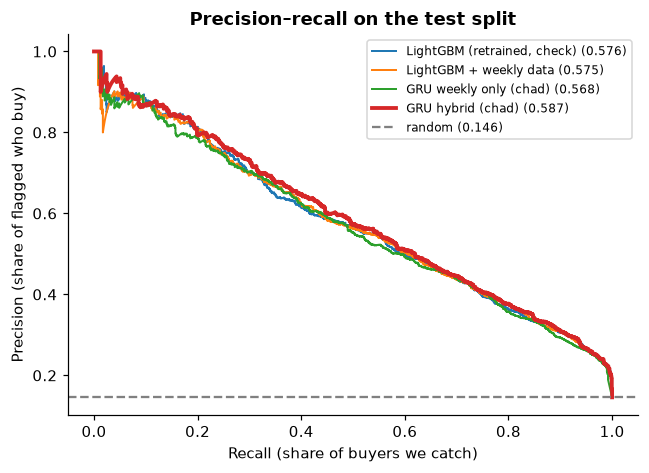

In [13]:
# PR curves for my models and the fair LightGBM check (the team's curves are in results/pr_curves.png)
fig, ax = plt.subplots(figsize=(6, 4.4))
for n in ["LightGBM (retrained, check)", "LightGBM + weekly data", "GRU weekly only (chad)", "GRU hybrid (chad)"]:
    pr, rc, _ = precision_recall_curve(y_test, test_scores[n])
    ax.plot(rc, pr, label=f"{n} ({average_precision_score(y_test, test_scores[n]):.3f})", lw=2.5 if "hybrid" in n else 1.3)
ax.axhline(y_test.mean(), color="grey", ls="--", label=f"random ({y_test.mean():.3f})")
ax.set_xlabel("Recall (share of buyers we catch)"); ax.set_ylabel("Precision (share of flagged who buy)")
ax.set_title("Precision–recall on the test split"); ax.legend(fontsize=8)
save(fig, "32_gru_pr_curves")

In [14]:
TOP_N = 1000
print(f"Of the top {TOP_N:,} test customers each model flags, how many bought (random ≈ {y_test.mean()*TOP_N:.0f}):")
for n in test_scores:
    print(f"  {n:<28} {precision_at_top(y_test, test_scores[n], TOP_N / len(y_test)) * TOP_N:,.0f}")

Of the top 1,000 test customers each model flags, how many bought (random ≈ 146):
  LightGBM (retrained, check)  596
  LightGBM + weekly data       606
  GRU hybrid (chad)            618
  GRU weekly only (chad)       604


### 6b. Is my model's lead real, or luck of the test sample? (paired bootstrap)
The test split is one sample of 9,600 customers. I re-draw it 1,000 times (with replacement),
score every model on the **same** re-drawn customers, and count how often my GRU is ahead.
If the 95% range of the difference stays above 0, the lead is unlikely to be luck.
(Logistic regression is refitted with the team's chosen setting from `01_baselines`, C = 0.01.)

In [15]:
from sklearn.pipeline import Pipeline
team_lr = Pipeline([("prep", build_preprocessor(X_train)),
                    ("model", LogisticRegression(C=0.01, class_weight="balanced", max_iter=2000,
                                                 random_state=SEED))]).fit(X_train, y_train)
others = {"Logistic regression": team_lr.predict_proba(X_test)[:, 1],
          "LightGBM": test_scores["LightGBM (retrained, check)"]}
mine_p = test_scores["GRU hybrid (chad)"]
rng = np.random.default_rng(SEED)
diffs = {name: [] for name in others}
for _ in range(1000):
    i = rng.integers(0, len(y_test), len(y_test))          # one re-drawn test set
    base = average_precision_score(y_test[i], mine_p[i])
    for name, p in others.items():
        diffs[name].append(base - average_precision_score(y_test[i], p[i]))
for name, d in diffs.items():
    d = np.array(d)
    print(f"GRU hybrid minus {name:<20}: {d.mean():+.4f}  95% range [{np.percentile(d, 2.5):+.4f}, "
          f"{np.percentile(d, 97.5):+.4f}]  GRU ahead in {np.mean(d > 0):.0%} of re-draws")

GRU hybrid minus Logistic regression : +0.0101  95% range [+0.0029, +0.0169]  GRU ahead in 99% of re-draws
GRU hybrid minus LightGBM            : +0.0118  95% range [+0.0040, +0.0197]  GRU ahead in 100% of re-draws


## 7. Trust checks
### 7a. Leakage: no week after the cutoff, and a shuffled-label test on the weekly data

In [16]:
print("Latest week in the table ends on the cutoff (src/weekly_sequences.py keeps only rows dated ≤ CUTOFF_DATE)")
flat52 = lambda name: SEQ[name][:, -52:].reshape(len(SEQ[name]), -1)
real = LogisticRegression(max_iter=2000).fit(flat52("train"), y_train).predict_proba(flat52("val"))[:, 1]
print(f"Weekly data, REAL labels     → val ROC-AUC {roc_auc_score(y_val, real):.3f}   PR-AUC {average_precision_score(y_val, real):.3f}")
for k in range(5):                               # 5 different shuffles of the training labels
    ys = np.random.default_rng(k).permutation(y_train)
    p = LogisticRegression(max_iter=2000).fit(flat52("train"), ys).predict_proba(flat52("val"))[:, 1]
    print(f"Weekly data, SHUFFLED run {k} → val ROC-AUC {roc_auc_score(y_val, p):.3f}   PR-AUC {average_precision_score(y_val, p):.3f}")
print(f"My model's test ROC-AUC: {roc_auc_score(y_test, test_scores['GRU hybrid (chad)']):.3f} (> 0.95 would be suspicious)")

Latest week in the table ends on the cutoff (src/weekly_sequences.py keeps only rows dated ≤ CUTOFF_DATE)


Weekly data, REAL labels     → val ROC-AUC 0.858   PR-AUC 0.539


Weekly data, SHUFFLED run 0 → val ROC-AUC 0.518   PR-AUC 0.250


Weekly data, SHUFFLED run 1 → val ROC-AUC 0.471   PR-AUC 0.197


Weekly data, SHUFFLED run 2 → val ROC-AUC 0.480   PR-AUC 0.221


Weekly data, SHUFFLED run 3 → val ROC-AUC 0.452   PR-AUC 0.198


Weekly data, SHUFFLED run 4 → val ROC-AUC 0.473   PR-AUC 0.207
My model's test ROC-AUC: 0.878 (> 0.95 would be suspicious)


**Reading this (a finding, not a bug):** with shuffled labels ROC-AUC falls to about **0.5** = random,
so nothing about the October purchases leaks into the weekly table. PR-AUC with shuffled labels stays a
bit *above* 0.146, though. Why? 23% of customers have **no activity at all** in the last year, so the
model gives all of them exactly the same score, and any random score pushes active customers to the
extremes. PR-AUC only looks at the **top** of the list, so active customers landing there lifts it even
with random labels. ROC-AUC looks at the whole ranking and isn't fooled. That's why I use ROC-AUC
for this check on the sequence data.

### 7b. Which weeks does the GRU rely on? (occlusion test on validation)
Blank out one block of weeks (set it to "no activity") and measure the drop in validation PR-AUC.

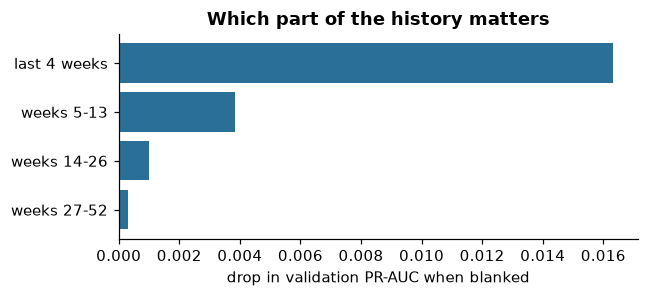

last 4 weeks    0.0163
weeks 5-13      0.0038
weeks 14-26     0.0010
weeks 27-52     0.0003
dtype: float64

In [17]:
no_activity = ((np.log1p(0) - CH_MEAN) / CH_STD).astype(np.float32)   # what an empty week looks like after scaling
base = average_precision_score(y_val, predict_proba(final, Q_va, S_va, W))
blocks = {"last 4 weeks": (1, 4), "weeks 5-13": (5, 13), "weeks 14-26": (14, 26), "weeks 27-52": (27, 52)}
drops = {}
for label, (a, b) in blocks.items():
    if a > W: continue
    Q = Q_va.clone()
    Q[:, -min(b, W):Q.shape[1] - a + 1] = torch.tensor(no_activity)   # weeks a..b before the cutoff
    drops[label] = base - average_precision_score(y_val, predict_proba(final, Q, S_va, W))
drops = pd.Series(drops)
fig, ax = plt.subplots(figsize=(6, 2.8))
ax.barh(drops.index[::-1], drops.values[::-1], color=BLUE)
ax.set_xlabel("drop in validation PR-AUC when blanked"); ax.set_title("Which part of the history matters")
save(fig, "33_gru_week_importance")
drops.round(4)

## 8. Save my model (git-ignored; for the agent in PR2)

In [18]:
torch.save({"state_dict": final.state_dict(), "config": best_cfg, "n_static": S_tr.shape[1],
            "channel_mean": CH_MEAN, "channel_std": CH_STD, "threshold": thresholds["GRU hybrid (chad)"]},
           MODELS_DIR / "gru_chad.pt")
print("Saved models/gru_chad.pt")

Saved models/gru_chad.pt


## 9. Conclusions for Progress Review 1
*Fill in from the numbers above after Restart & Run All:* how the GRU hybrid compares with the team's
baselines on test PR-AUC; whether "LightGBM + weekly data" beat plain LightGBM (did the weekly data
add information?); the best tuning run and whether the spread is bigger than the seed noise; which
weeks matter in the occlusion test; the shuffled-label ROC-AUC.